### scipy: Messdaten auswerten - Übungen

Messwerte aus Experimenten, Wetterstationen oder Sensoren sind nur an einzelnen Stellen bekannt und streuen etwas.
In diesem Notebook wertest du solche Messreihen mit **scipy** aus: Zwischenwerte schätzen (**Interpolation**),
eine passende Funktion durch die Punkte legen (**Ausgleichskurven**), Messwerte aufsummieren und **Spitzen** in einer Messreihe finden.

Die Reihe hat vier Notebooks:

1. Analysis: Nullstellen, Gleichungen, Extremstellen, Integrale
2. **Messdaten auswerten**: Interpolation, Ausgleichskurven, Spitzen finden (dieses Notebook)
3. Stochastik: Verteilungen und Hypothesentests
4. Anwendungen: Änderungsraten und Modelle, lineare Optimierung, Abstände

Vorausgesetzt werden *scipy: Analysis*, *numpy: Mathematik* (Regression mit `np.polyfit()`) und *matplotlib: Grundlagen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Beim ersten `import scipy` lädt der Browser das Paket nach. Das dauert ein paar Sekunden.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ überlegst du zuerst, führst dann die Zelle aus und vergleichst.
Die aufklappbare Lösung erklärt dort, wie die Ausgabe zustande kommt.

## 1. Interpolation

#### Zwischenwerte schätzen

Eine Wetterstation misst die Temperatur nur alle drei Stunden. Wie warm war es um 10 Uhr?
Eine **Interpolation** legt eine Kurve genau durch alle Messpunkte und liefert damit Werte **zwischen** den Messstellen.

Das Modul `scipy.interpolate` hat dafür mehrere Verfahren. Die einfachste ist die **lineare Interpolation**: Benachbarte Punkte werden
durch Strecken verbunden. `interpolate.make_interp_spline(x, y, k=1)` gibt eine Funktion zurück, die man wie jede Funktion aufruft.
Das Ergebnis ist ein Array (bei einer einzelnen Zahl ein Array ohne Achsen), das man mit `float()` in eine Zahl umwandelt.

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])

linear = interpolate.make_interp_spline(stunde, temperatur, k=1)
print(linear(10))
print(float(linear(10)))
print(linear(np.array([1.5, 10, 13])))

#### Glatte Kurven: `CubicSpline`

Die Strecken der linearen Interpolation haben an den Messpunkten Knicke. Natürliche Vorgänge verlaufen meist glatt.
`interpolate.CubicSpline(x, y)` setzt die Kurve aus Polynomen 3. Grades zusammen, die an den Messpunkten ohne Knick ineinander übergehen
(ein **kubischer Spline**). Die Messstellen `x` müssen dafür aufsteigend sortiert sein.

Außerhalb der Messwerte (hier also vor 0 Uhr oder nach 24 Uhr) liefern beide Verfahren nur eine grobe Vermutung, man spricht von **Extrapolation**.

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
import matplotlib.pyplot as plt

spline = interpolate.CubicSpline(stunde, temperatur)
linear = interpolate.make_interp_spline(stunde, temperatur, k=1)
print(round(float(spline(10)), 2))
x = np.linspace(0, 24, 200)
plt.plot(stunde, temperatur, 'ko', label='Messwerte')
plt.plot(x, linear(x), label='linear')
plt.plot(x, spline(x), label='CubicSpline')
plt.legend()
plt.show()

#### Steigung und Fläche

Ein `CubicSpline` kann noch mehr:

- `spline(x, 1)` ist die **Ableitung** an der Stelle `x` (die Steigung, hier: um wie viel Grad pro Stunde die Temperatur steigt).
- `spline.integrate(a, b)` ist das **Integral** von `a` bis `b`. Geteilt durch `b - a` ergibt es den Mittelwert.

Die Stelle der höchsten Temperatur findet man mit `minimize_scalar()` aus *scipy: Analysis*. Dazu braucht man eine Funktion,
die eine Zahl zurückgibt, z. B. `-float(spline(x))`.

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
from scipy import optimize

spline = interpolate.CubicSpline(stunde, temperatur)
print(round(float(spline(10, 1)), 2))
print(round(float(spline.integrate(0, 24)) / 24, 2))


def minus_temperatur(x):
    return -float(spline(x))


e = optimize.minimize_scalar(minus_temperatur, bounds=(12, 18))
print(round(e.x, 2), round(-e.fun, 2))

#### Aufgabe 1.1

Gib mit linearer Interpolation die Temperaturen um 1 Uhr, 10 Uhr und 22:30 Uhr (22.5) aus, jeweils auf eine Nachkommastelle.

**Erwartete Ausgabe:**
```
1 8.5
10 13.3
22.5 11.0
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
linear = interpolate.make_interp_spline(stunde, temperatur, k=1)
for x in [1, 10, 22.5]:
    print(x, round(float(linear(x)), 1))
```

</details>

#### Aufgabe 1.2

Gib dieselben drei Temperaturen mit `CubicSpline` aus (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
1 8.77
10 13.43
22.5 10.68
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
spline = interpolate.CubicSpline(stunde, temperatur)
for x in [1, 10, 22.5]:
    print(x, round(float(spline(x)), 2))
```

</details>

#### Aufgabe 1.3

Prüfe, dass der Spline genau durch die Messpunkte geht: Gib die Werte des Splines an allen Messstellen aus (auf 6 Stellen gerundet)
und danach, ob sie mit `np.allclose()` mit den Messwerten übereinstimmen.

**Erwartete Ausgabe:**
```
[ 9.   7.5  7.  11.5 17.  19.5 16.  12.  10. ]
True
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
spline = interpolate.CubicSpline(stunde, temperatur)
print(np.round(spline(stunde), 6))
print(np.allclose(spline(stunde), temperatur))
```

</details>

#### Aufgabe 1.4

Erzeuge mit dem Spline eine Tabelle der Temperaturen für jede volle Stunde von 0 bis 24 (25 Werte, eine Nachkommastelle).

**Erwartete Ausgabe:**
```
[ 9.   8.8  8.2  7.5  6.9  6.7  7.   8.   9.6 11.5 13.4 15.3 17.  18.4
 19.3 19.5 18.8 17.5 16.  14.5 13.2 12.  11.1 10.4 10. ]
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
spline = interpolate.CubicSpline(stunde, temperatur)
print(np.round(spline(np.arange(25)), 1))
```

</details>

#### Aufgabe 1.5

Ein Wanderweg wird alle 2 km vermessen. Gib mit `CubicSpline` die Höhe bei km 5 und bei km 11 aus (ganze Meter mit `round()`)
und mit linearer Interpolation zum Vergleich.

**Erwartete Ausgabe:**
```
5 507 495
11 548 495
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
spline = interpolate.CubicSpline(km, hoehe)
linear = interpolate.make_interp_spline(km, hoehe, k=1)
for x in [5, 11]:
    print(x, round(float(spline(x))), round(float(linear(x))))
```

</details>

#### Aufgabe 1.6

Gib die Steigung des Wanderwegs (nach dem Spline) bei km 1, 5 und 11 in Metern pro km aus und in Prozent
(Meter pro 1000 m mal 100), jeweils auf eine Nachkommastelle.

**Erwartete Ausgabe:**
```
1 31.1 3.1
5 28.2 2.8
11 -55.8 -5.6
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
spline = interpolate.CubicSpline(km, hoehe)
for x in [1, 5, 11]:
    m = float(spline(x, 1))
    print(x, round(m, 1), round(m / 1000 * 100, 1))
```

</details>

#### Aufgabe 1.7

Wo ist der Wanderweg (nach dem Spline) am steilsten? Berechne die Steigung an 1201 Stellen von 0 bis 12 und gib die Stelle mit dem größten Betrag
der Steigung und die Steigung dort aus (eine Nachkommastelle).

**Erwartete Ausgabe:**
```
12.0 -189.0
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
spline = interpolate.CubicSpline(km, hoehe)
x = np.linspace(0, 12, 1201)
steigung = spline(x, 1)
i = np.abs(steigung).argmax()
print(round(x[i], 1), round(steigung[i], 1))
```

</details>

#### Aufgabe 1.8

Berechne die mittlere Tagestemperatur auf zwei Wegen: als Mittelwert der Messwerte (ohne den doppelten Wert um 24 Uhr, also `temperatur[:-1]`)
und als Integral des Splines von 0 bis 24 geteilt durch 24. Gib beides auf zwei Nachkommastellen aus.

**Erwartete Ausgabe:**
```
12.44
12.51
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
spline = interpolate.CubicSpline(stunde, temperatur)
print(round(temperatur[:-1].mean(), 2))
print(round(float(spline.integrate(0, 24)) / 24, 2))
```

</details>

#### Aufgabe 1.9

Bestimme die tiefste Temperatur in der Nacht nach dem Spline (zwischen 0 und 9 Uhr): Uhrzeit und Temperatur, je zwei Nachkommastellen.

**Erwartete Ausgabe:**
```
4.99 6.67
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
from scipy import optimize
spline = interpolate.CubicSpline(stunde, temperatur)


def temp(x):
    return float(spline(x))


e = optimize.minimize_scalar(temp, bounds=(0, 9))
print(round(e.x, 2), round(e.fun, 2))
```

</details>

#### Aufgabe 1.10

Ab wann war es nach dem Spline am Vormittag wärmer als 15 °C? Bestimme die Nullstelle von `spline(x) - 15` mit `brentq()`
zwischen 9 und 12 und gib die Uhrzeit in Stunden (zwei Nachkommastellen) und im Format `hh:mm` aus.

**Erwartete Ausgabe:**
```
10.83
10:50
```

In [ ]:
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

stunde = np.array([0, 3, 6, 9, 12, 15, 18, 21, 24])
temperatur = np.array([9.0, 7.5, 7.0, 11.5, 17.0, 19.5, 16.0, 12.0, 10.0])
from scipy import optimize
spline = interpolate.CubicSpline(stunde, temperatur)


def h(x):
    return float(spline(x)) - 15


x0 = optimize.brentq(h, 9, 12)
print(round(x0, 2))
minuten = round(x0 * 60)
print(f'{minuten // 60:02d}:{minuten % 60:02d}')
```

</details>

#### Aufgabe 1.11

Zeichne das Höhenprofil des Wanderwegs: die Messpunkte als schwarze Punkte, den Spline als grüne Linie (300 Punkte von 0 bis 12),
die Achsen beschriftet mit `km` und `Höhe in m`.

**Erwartete Ausgabe:**

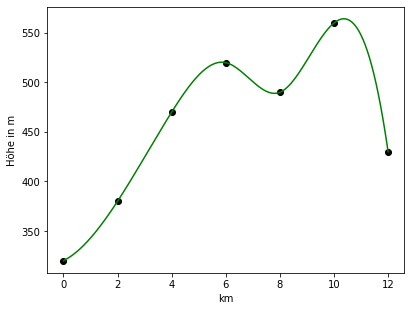

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
import matplotlib.pyplot as plt
spline = interpolate.CubicSpline(km, hoehe)
x = np.linspace(0, 12, 300)
plt.plot(km, hoehe, 'ko')
plt.plot(x, spline(x), color='green')
plt.xlabel('km')
plt.ylabel('Höhe in m')
plt.show()
```

</details>

#### Aufgabe 1.12

Wie viele Höhenmeter geht man auf dem Wanderweg insgesamt bergauf? Werte den Spline an 1201 Stellen aus, bilde mit `np.diff()` die Differenzen
benachbarter Werte und addiere nur die positiven. Gib das Ergebnis in ganzen Metern aus.

**Erwartete Ausgabe:**
```
276
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
spline = interpolate.CubicSpline(km, hoehe)
h = spline(np.linspace(0, 12, 1201))
d = np.diff(h)
print(round(d[d > 0].sum()))
```

</details>

#### Aufgabe 1.13

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import interpolate

x = np.array([0, 2, 4])
y = np.array([10, 20, 0])
linear = interpolate.make_interp_spline(x, y, k=1)
print(float(linear(1)), float(linear(3)), float(linear(4)))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
15.0 10.0 0.0
```

Die lineare Interpolation verbindet die Punkte durch Strecken.
- Bei `x = 1` liegt man in der Mitte zwischen (0|10) und (2|20), also `15.0`.
- Bei `x = 3` in der Mitte zwischen (2|20) und (4|0), also `10.0`.
- Bei `x = 4` liegt ein Messpunkt, dort kommt genau der Messwert `0.0` heraus.

</details>

#### Aufgabe 1.14

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import interpolate

x = np.array([0, 1, 2, 3])
y = 2 * x + 1
spline = interpolate.CubicSpline(x, y)
print(round(float(spline(1.5)), 4))
print(round(float(spline(1.5, 1)), 4))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
4.0
2.0
```

Die Messpunkte liegen alle auf der Geraden `y = 2x + 1`. Die glatteste Kurve durch sie ist diese Gerade selbst.
Deshalb ist der Wert bei 1.5 genau `2 · 1.5 + 1 = 4.0` und die Steigung überall `2.0`.

</details>

## 2. Ausgleichskurven mit curve_fit

#### Ein Modell an Messwerte anpassen

Bei der Interpolation geht die Kurve genau durch alle Punkte. Messwerte streuen aber, und oft weiß man, welche **Art** von Funktion
den Vorgang beschreibt (exponentielles Wachstum, Abkühlung, ...). Dann sucht man die Funktion dieser Art, die am besten zu den Punkten passt:
eine **Ausgleichskurve**. `np.polyfit()` kann das nur für Polynome, `optimize.curve_fit()` für jede Funktion.

1. Das **Modell** als Funktion schreiben: zuerst `x`, dann die gesuchten **Parameter**, z. B. `def modell(x, a, k): return a * np.exp(k * x)`.
2. `parameter, kovarianz = optimize.curve_fit(modell, x, y)` liefert ein Array mit den besten Werten der Parameter
   (die *Kovarianz* gibt an, wie genau sie bestimmt sind; sie wird hier nicht gebraucht).
3. Mit `modell(x, *parameter)` rechnet man Werte aus. Der Stern `*` packt das Array in einzelne Argumente aus.

„Am besten“ heißt wie bei der Regression: Die Summe der quadrierten Abweichungen ist am kleinsten.

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, k):
    return a * np.exp(k * t)


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
a, k = parameter
print(round(a, 2), round(k, 4))
print(round(modell(8, a, k)))
print(round(modell(8, *parameter)))

#### Startwerte mit `p0=`

`curve_fit()` probiert ausgehend von **Startwerten** für die Parameter immer bessere Werte aus. Ohne Angabe beginnt es mit 1 für alle.
Liegen die richtigen Werte weit davon entfernt, findet es manchmal keine Lösung (ein `RuntimeError`) oder eine schlechte.
Dann gibt man mit `p0=[...]` grob geschätzte Startwerte an, z. B. den ersten Messwert und eine typische Rate.

Beispiel: Abkühlung eines Tees. Die Temperatur nähert sich der Raumtemperatur `u`, der Abstand nimmt exponentiell ab:
`T(t) = u + (T0 - u) · e^(-k·t)`.

In [ ]:
import numpy as np
from scipy import optimize

minute = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50])
temperatur = np.array([85.0, 68.5, 56.0, 46.5, 39.5, 34.5, 30.5, 25.5, 23.0])


def abkuehlung(t, u, t0, k):
    return u + (t0 - u) * np.exp(-k * t)


parameter, kovarianz = optimize.curve_fit(abkuehlung, minute, temperatur, p0=[20, 85, 0.1])
u, t0, k = parameter
print(round(u, 2), round(t0, 2), round(k, 4))

#### Wie gut passt das Modell?

Die **Residuen** sind die Abweichungen der Messwerte vom Modell. Aus ihnen berechnet man das **Bestimmtheitsmaß**

`R² = 1 - (Summe der quadrierten Residuen) / (Summe der quadrierten Abweichungen vom Mittelwert)`.

Es liegt höchstens bei 1 (alle Punkte auf der Kurve). Mit `R²` kann man verschiedene Modelle für dieselben Messwerte vergleichen.

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, k):
    return a * np.exp(k * t)


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
residuen = anzahl - modell(stunde, *parameter)
print(np.round(residuen, 1))
r2 = 1 - (residuen ** 2).sum() / ((anzahl - anzahl.mean()) ** 2).sum()
print(round(r2, 4))

#### Aufgabe 2.1

Passe eine Gerade `y = m·x + b` mit `curve_fit()` an die Federmessung an (`stats` wird hier nicht gebraucht).
Gib `m` und `b` auf 4 Nachkommastellen aus und vergleiche mit `np.polyfit(masse, laenge, 1)`.

**Erwartete Ausgabe:**
```
[0.0505 9.8533]
[0.0505 9.8533]
```

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
from scipy import optimize
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
from scipy import optimize


def gerade(x, m, b):
    return m * x + b


parameter, kovarianz = optimize.curve_fit(gerade, masse, laenge)
print(np.round(parameter, 4))
print(np.round(np.polyfit(masse, laenge, 1), 4))
```

</details>

#### Aufgabe 2.2

Die Bakterienzahl wächst exponentiell: `N(t) = a · e^(k·t)`. Bestimme `a` und `k` (zwei bzw. 4 Nachkommastellen) und die
Verdopplungszeit `ln(2) / k` in Stunden (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
117.52 0.4041
1.72
```

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, k):
    return a * np.exp(k * t)


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
a, k = parameter
print(round(a, 2), round(k, 4))
print(round(np.log(2) / k, 2))
```

</details>

#### Aufgabe 2.3

Wann werden es nach dem Modell der vorigen Aufgabe 10000 Bakterien sein? Löse `N(t) = 10000` mit `brentq()` im Intervall von 0 bis 20
(zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
11.0
```

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, k):
    return a * np.exp(k * t)


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)


def h(t):
    return modell(t, *parameter) - 10000


print(round(optimize.brentq(h, 0, 20), 2))
```

</details>

#### Aufgabe 2.4

Passe für die Bakterien das Modell `N(t) = a · b^t` an (`b` ist der Wachstumsfaktor pro Stunde). Gib `a` und `b` auf 4 Nachkommastellen aus und
das prozentuale Wachstum pro Stunde (`(b - 1) · 100`, eine Nachkommastelle).

**Erwartete Ausgabe:**
```
117.525 1.498
49.8
```

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, b):
    return a * b ** t


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
a, b = parameter
print(round(a, 4), round(b, 4))
print(round((b - 1) * 100, 1))
```

</details>

#### Aufgabe 2.5

Bestimme für den Tee mit dem Abkühlungsmodell aus dem Beispiel, wann er auf 40 °C abgekühlt ist (`brentq()` zwischen 0 und 50) und
welche Temperatur er nach 60 Minuten hat. Runde auf zwei Nachkommastellen.

**Erwartete Ausgabe:**
```
19.69
21.28
```

In [ ]:
import numpy as np
from scipy import optimize

minute = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50])
temperatur = np.array([85.0, 68.5, 56.0, 46.5, 39.5, 34.5, 30.5, 25.5, 23.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

minute = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50])
temperatur = np.array([85.0, 68.5, 56.0, 46.5, 39.5, 34.5, 30.5, 25.5, 23.0])


def abkuehlung(t, u, t0, k):
    return u + (t0 - u) * np.exp(-k * t)


parameter, kovarianz = optimize.curve_fit(abkuehlung, minute, temperatur, p0=[20, 85, 0.1])


def h(t):
    return abkuehlung(t, *parameter) - 40


print(round(optimize.brentq(h, 0, 50), 2))
print(round(abkuehlung(60, *parameter), 2))
```

</details>

#### Aufgabe 2.6

Zeichne die Messwerte des Tees als rote Punkte und die angepasste Abkühlungskurve als blaue Linie (200 Punkte von 0 bis 60).
Zeichne die Raumtemperatur `u` des Modells als gestrichelte graue Linie ein (`plt.axhline(u, color='gray', linestyle='--')`).

**Erwartete Ausgabe:**

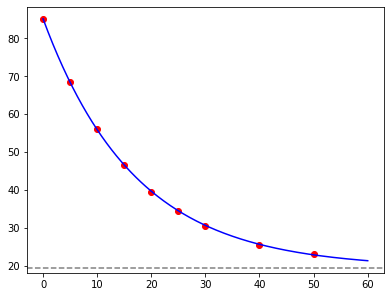

In [ ]:
import numpy as np
from scipy import optimize

minute = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50])
temperatur = np.array([85.0, 68.5, 56.0, 46.5, 39.5, 34.5, 30.5, 25.5, 23.0])
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

minute = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50])
temperatur = np.array([85.0, 68.5, 56.0, 46.5, 39.5, 34.5, 30.5, 25.5, 23.0])
import matplotlib.pyplot as plt


def abkuehlung(t, u, t0, k):
    return u + (t0 - u) * np.exp(-k * t)


parameter, kovarianz = optimize.curve_fit(abkuehlung, minute, temperatur, p0=[20, 85, 0.1])
x = np.linspace(0, 60, 200)
plt.plot(minute, temperatur, 'ro')
plt.plot(x, abkuehlung(x, *parameter), color='blue')
plt.axhline(parameter[0], color='gray', linestyle='--')
plt.show()
```

</details>

#### Aufgabe 2.7

Ein Kondensator wird aufgeladen. Die Spannung nähert sich der Endspannung `U0`: `U(t) = U0 · (1 - e^(-t/τ))` (τ: Zeitkonstante).
Bestimme `U0` und `τ` mit den Startwerten `p0=[10, 1]` (zwei Nachkommastellen). Nach welcher Zeit ist der Kondensator zu 99 % geladen (`τ · ln(100)`)?

**Erwartete Ausgabe:**
```
10.19 1.38
6.34
```

In [ ]:
import numpy as np
from scipy import optimize

t = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0])   # in s
u = np.array([0.0, 3.1, 5.2, 6.8, 7.8, 9.1, 9.6, 9.9])    # in V
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

t = np.array([0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0])   # in s
u = np.array([0.0, 3.1, 5.2, 6.8, 7.8, 9.1, 9.6, 9.9])    # in V


def laden(t, u0, tau):
    return u0 * (1 - np.exp(-t / tau))


parameter, kovarianz = optimize.curve_fit(laden, t, u, p0=[10, 1])
u0, tau = parameter
print(round(u0, 2), round(tau, 2))
print(round(tau * np.log(100), 2))
```

</details>

#### Aufgabe 2.8

Die Anzahl der Nutzer einer neuen App wächst erst schnell und dann immer langsamer bis zu einer Grenze `G` (**logistisches Wachstum**):
`N(t) = G / (1 + a · e^(-k·t))`. Bestimme `G`, `a` und `k` mit den Startwerten `p0=[5000, 50, 1]` (`G` ganzzahlig, `a` mit zwei, `k` mit 4 Nachkommastellen)
und den Zeitpunkt, an dem die Hälfte von `G` erreicht ist (`ln(a) / k`, zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
4334 41.32 0.7589
4.9
```

In [ ]:
import numpy as np
from scipy import optimize

woche = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
nutzer = np.array([95, 210, 430, 830, 1450, 2250, 3020, 3600, 3950, 4150, 4250])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

woche = np.array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
nutzer = np.array([95, 210, 430, 830, 1450, 2250, 3020, 3600, 3950, 4150, 4250])


def logistisch(t, g, a, k):
    return g / (1 + a * np.exp(-k * t))


parameter, kovarianz = optimize.curve_fit(logistisch, woche, nutzer, p0=[5000, 50, 1])
g, a, k = parameter
print(round(g), round(a, 2), round(k, 4))
print(round(np.log(a) / k, 2))
```

</details>

#### Aufgabe 2.9

Vergleiche für die Bakterien eine Regressionsparabel (`np.polyfit(..., 2)`) mit dem exponentiellen Modell: Gib für beide `R²` (6 Nachkommastellen)
und die Vorhersage für 10 Stunden (ganzzahlig) aus.

**Erwartete Ausgabe:**
```
0.995527 3539
0.999871 6688
```

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])


def modell(t, a, k):
    return a * np.exp(k * t)


def r2(y, y_modell):
    return 1 - ((y - y_modell) ** 2).sum() / ((y - y.mean()) ** 2).sum()


parabel = np.polyfit(stunde, anzahl, 2)
parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
print(round(r2(anzahl, np.polyval(parabel, stunde)), 6), round(np.polyval(parabel, 10)))
print(round(r2(anzahl, modell(stunde, *parameter)), 6), round(modell(10, *parameter)))
```

</details>

#### Aufgabe 2.10

Gezeiten: Der Wasserstand in einem Hafen (in m) schwankt etwa wie eine Sinuskurve `h(t) = m + a · sin(2π (t - c) / p)`.
Bestimme `m`, `a`, `c` und die Periode `p` mit den Startwerten `p0=[3, 1.5, 3, 12]` (zwei Nachkommastellen).

**Erwartete Ausgabe:**
```
[ 3.08  1.49  3.27 13.28]
```

In [ ]:
import numpy as np
from scipy import optimize

stunde = np.array([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24])
pegel = np.array([1.9, 2.3, 3.6, 4.5, 4.3, 3.0, 1.8, 1.5, 2.6, 4.0, 4.6, 3.9, 2.4])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize

stunde = np.array([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24])
pegel = np.array([1.9, 2.3, 3.6, 4.5, 4.3, 3.0, 1.8, 1.5, 2.6, 4.0, 4.6, 3.9, 2.4])


def gezeiten(t, m, a, c, p):
    return m + a * np.sin(2 * np.pi * (t - c) / p)


parameter, kovarianz = optimize.curve_fit(gezeiten, stunde, pegel, p0=[3, 1.5, 3, 12])
print(np.round(parameter, 2))
```

</details>

#### Aufgabe 2.11

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import optimize


def modell(x, a, b):
    return a * x + b


x = np.array([0, 1, 2, 3])
y = np.array([1.1, 2.9, 4.9, 7.1])
parameter, kovarianz = optimize.curve_fit(modell, x, y)
print(len(parameter))
print(np.round(parameter, 1))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
2
[2. 1.]
```

- Das Modell hat zwei Parameter `a` und `b`, also enthält `parameter` zwei Werte.
- Die Punkte liegen fast auf der Geraden `y = 2x + 1` (die Abweichungen von ±0.1 heben sich auf). Gerundet: `[2. 1.]`.

</details>

## 3. Regression mit scipy.stats

#### `stats.linregress()`

Für die **Regressionsgerade** gibt es im Modul `scipy.stats` (*Statistik*) die Funktion `stats.linregress(x, y)`.
Sie berechnet in einem Schritt alles, was man zur Geraden braucht:

| Attribut | Bedeutung |
|---|---|
| `slope` | Steigung `m` |
| `intercept` | Achsenabschnitt `b` |
| `rvalue` | Korrelationskoeffizient `r` (zwischen -1 und 1), `rvalue ** 2` ist das Bestimmtheitsmaß |

Es liefert dasselbe wie `np.polyfit(x, y, 1)` und `np.corrcoef()` zusammen.

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm

r = stats.linregress(masse, laenge)
print(round(r.slope, 4), round(r.intercept, 4))
print(round(r.rvalue, 4), round(r.rvalue ** 2, 4))
print(np.round(np.polyfit(masse, laenge, 1), 4))

#### `stats.pearsonr()`

Wer nur den Korrelationskoeffizienten braucht, nimmt `stats.pearsonr(x, y)` (nach Karl Pearson).
Der Koeffizient steht im Attribut `statistic`. Das Ergebnis enthält außerdem einen `pvalue`: Er gehört zu den Hypothesentests,
die im Notebook *scipy: Stochastik* behandelt werden.

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm

ergebnis = stats.pearsonr(masse, laenge)
print(round(ergebnis.statistic, 4))
print(round(np.corrcoef(masse, laenge)[0, 1], 4))

#### Aufgabe 3.1

Bestimme für die Federmessung Steigung, Achsenabschnitt und `R²` mit `linregress()` (4 Nachkommastellen).

**Erwartete Ausgabe:**
```
0.0505 9.8533 0.9996
```

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
r = stats.linregress(masse, laenge)
print(round(r.slope, 4), round(r.intercept, 4), round(r.rvalue ** 2, 4))
```

</details>

#### Aufgabe 3.2

Nach dem Gesetz von Hooke ist die Verlängerung proportional zur Masse. Gib die Länge der Feder ohne Gewicht (Achsenabschnitt) aus und die Masse,
bei der die Feder nach der Regressionsgeraden 30 cm lang ist (beides auf eine Nachkommastelle).

**Erwartete Ausgabe:**
```
9.9
399.3
```

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
r = stats.linregress(masse, laenge)
print(round(r.intercept, 1))
print(round((30 - r.intercept) / r.slope, 1))
```

</details>

#### Aufgabe 3.3

Untersuche, ob Körpergröße und Schuhgröße zusammenhängen: Gib den Korrelationskoeffizienten mit `pearsonr()` (4 Nachkommastellen) und die
Regressionsgerade aus. Welche Schuhgröße sagt sie für 180 cm voraus (eine Nachkommastelle)?

**Erwartete Ausgabe:**
```
0.9799
0.2623 -4.686
42.5
```

In [ ]:
import numpy as np
from scipy import stats

groesse = np.array([158, 162, 165, 168, 170, 172, 175, 178, 181, 185, 188, 192])
schuh = np.array([37, 38, 39, 38, 40, 41, 41, 42, 43, 43, 45, 46])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

groesse = np.array([158, 162, 165, 168, 170, 172, 175, 178, 181, 185, 188, 192])
schuh = np.array([37, 38, 39, 38, 40, 41, 41, 42, 43, 43, 45, 46])
print(round(stats.pearsonr(groesse, schuh).statistic, 4))
r = stats.linregress(groesse, schuh)
print(round(r.slope, 4), round(r.intercept, 4))
print(round(r.slope * 180 + r.intercept, 1))
```

</details>

#### Aufgabe 3.4

Zeichne die Federmessung als blaue Punkte und die Regressionsgerade aus `linregress()` als rote Linie von 0 bis 350 g.
Schreibe die Geradengleichung mit zwei Nachkommastellen als Titel (z. B. `y = 0.05x + 9.80`).

**Erwartete Ausgabe:**

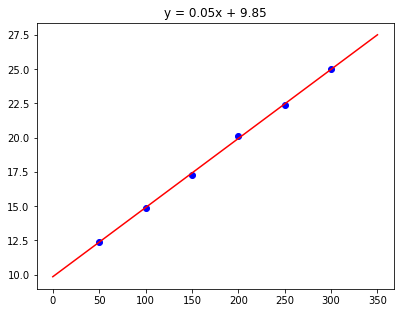

In [ ]:
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import stats

masse = np.array([50, 100, 150, 200, 250, 300])           # in g
laenge = np.array([12.4, 14.9, 17.3, 20.1, 22.4, 25.0])   # in cm
import matplotlib.pyplot as plt
r = stats.linregress(masse, laenge)
x = np.array([0, 350])
plt.plot(masse, laenge, 'bo')
plt.plot(x, r.slope * x + r.intercept, color='red')
plt.title(f'y = {r.slope:.2f}x + {r.intercept:.2f}')
plt.show()
```

</details>

#### Aufgabe 3.5

Für die Bakterien aus Abschnitt 2 kann man auch eine Gerade durch die Punkte `(t, ln(N))` legen (wie in *numpy: Mathematik*).
Bestimme sie mit `linregress()` und gib `k = slope` und `a = e^intercept` auf 4 bzw. zwei Nachkommastellen aus. Vergleiche mit `curve_fit()`.

**Erwartete Ausgabe:**
```
0.4023 118.43
0.4041 117.52
```

In [ ]:
import numpy as np
from scipy import optimize, stats

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, stats

stunde = np.array([0, 1, 2, 3, 4, 5, 6])
anzahl = np.array([120, 175, 265, 390, 600, 880, 1330])
r = stats.linregress(stunde, np.log(anzahl))
print(round(r.slope, 4), round(np.exp(r.intercept), 2))


def modell(t, a, k):
    return a * np.exp(k * t)


parameter, kovarianz = optimize.curve_fit(modell, stunde, anzahl)
print(round(parameter[1], 4), round(parameter[0], 2))
```

</details>

#### Aufgabe 3.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import stats

x = np.array([1, 2, 3, 4, 5])
y = 10 - 2 * x
r = stats.linregress(x, y)
print(round(r.slope, 2), round(r.intercept, 2), round(r.rvalue, 2))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
-2.0 10.0 -1.0
```

Die Punkte liegen genau auf der fallenden Geraden `y = -2x + 10`. Steigung `-2.0`, Achsenabschnitt `10.0`.
Der Korrelationskoeffizient ist bei einem exakten fallenden Zusammenhang `-1.0`.

</details>

## 4. Messreihen aufsummieren und ableiten

#### `integrate.cumulative_trapezoid()`

`np.trapezoid(y, x)` berechnet die **gesamte** Fläche unter den Messpunkten. `integrate.cumulative_trapezoid(y, x, initial=0)` berechnet die Fläche
**bis zu jedem Messpunkt**: also z. B. aus der Geschwindigkeit den Weg, der bis zu jedem Zeitpunkt zurückgelegt wurde.
`initial=0` setzt den Wert am ersten Punkt auf 0, sonst wäre das Ergebnis um einen Wert kürzer als die Messreihe.

In [ ]:
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s

weg = integrate.cumulative_trapezoid(geschwindigkeit, zeit, initial=0)
print(weg)
print(np.trapezoid(geschwindigkeit, zeit))

#### Die Gegenrichtung: `np.gradient()`

Aus Messwerten einer Größe bekommt man ihre **Änderungsrate** (z. B. aus dem Weg die Geschwindigkeit) mit `np.gradient(y, x)`.
Für jeden Messpunkt wird die Steigung zu den Nachbarpunkten berechnet (an den Rändern nur zu einem Nachbarn).

In [ ]:
import numpy as np

zeit = np.array([0, 1, 2, 3, 4])
weg = np.array([0, 1, 4, 9, 16])
print(np.gradient(weg, zeit))

#### Aufgabe 4.1

Gib den bis zu jedem Messzeitpunkt zurückgelegten Weg der Fahrt aus und danach den gesamten Weg in km.

**Erwartete Ausgabe:**
```
[  0.  40. 150. 305. 475. 620. 680.]
0.68
```

In [ ]:
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
weg = integrate.cumulative_trapezoid(geschwindigkeit, zeit, initial=0)
print(weg)
print(weg[-1] / 1000)
```

</details>

#### Aufgabe 4.2

Ein Regenmesser misst die Regenmenge pro Stunde (in mm/h) zu jeder vollen Stunde. Gib aus, wie viel Regen bis zu jeder Stunde insgesamt gefallen ist,
und die erste Stunde, zu der es mehr als 10 mm waren.

**Erwartete Ausgabe:**
```
[ 0.    0.25  1.5   4.75  8.5  10.75 12.75 14.5  15.  ]
5
```

In [ ]:
import numpy as np
from scipy import integrate

stunde = np.arange(9)
regen = np.array([0.0, 0.5, 2.0, 4.5, 3.0, 1.5, 2.5, 1.0, 0.0])   # in mm/h
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate

stunde = np.arange(9)
regen = np.array([0.0, 0.5, 2.0, 4.5, 3.0, 1.5, 2.5, 1.0, 0.0])   # in mm/h
summe = integrate.cumulative_trapezoid(regen, stunde, initial=0)
print(summe)
print(stunde[summe > 10][0])
```

</details>

#### Aufgabe 4.3

In einen Tank fließt Wasser zu (positive Werte, in Liter pro Minute) und ab (negative Werte). Zu Beginn sind 200 l im Tank.
Gib die Füllmenge zu jedem Messzeitpunkt aus und die größte Füllmenge.

**Erwartete Ausgabe:**
```
[200. 270. 335. 365. 350. 295. 245.]
365.0
```

In [ ]:
import numpy as np
from scipy import integrate

minute = np.array([0, 5, 10, 15, 20, 25, 30])
zufluss = np.array([12, 16, 10, 2, -8, -14, -6])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate

minute = np.array([0, 5, 10, 15, 20, 25, 30])
zufluss = np.array([12, 16, 10, 2, -8, -14, -6])
menge = 200 + integrate.cumulative_trapezoid(zufluss, minute, initial=0)
print(menge)
print(menge.max())
```

</details>

#### Aufgabe 4.4

Berechne aus den Geschwindigkeiten der Fahrt mit `np.gradient()` die Beschleunigungen (in m/s²) und gib den Zeitpunkt der stärksten Bremsung
(kleinste Beschleunigung) aus.

**Erwartete Ausgabe:**
```
[ 0.8   0.7   0.45  0.15 -0.25 -0.85 -1.2 ]
60
```

In [ ]:
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
a = np.gradient(geschwindigkeit, zeit)
print(a)
print(zeit[a.argmin()])
```

</details>

#### Aufgabe 4.5

Ein Ball fällt. Die gemessenen Höhen (in m) gehören zu den Zeiten (in s). Berechne mit `np.gradient()` die Geschwindigkeiten und daraus noch einmal
mit `np.gradient()` die Beschleunigungen, beide auf zwei Nachkommastellen.

**Erwartete Ausgabe:**
```
[-0.5  -1.   -1.95 -2.9  -3.9  -4.9  -5.4 ]
[ -5.    -7.25  -9.5   -9.75 -10.    -7.5   -5.  ]
```

In [ ]:
import numpy as np

zeit = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
hoehe = np.array([2.00, 1.95, 1.80, 1.56, 1.22, 0.78, 0.24])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np

zeit = np.array([0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
hoehe = np.array([2.00, 1.95, 1.80, 1.56, 1.22, 0.78, 0.24])
v = np.gradient(hoehe, zeit)
print(np.round(v, 2))
print(np.round(np.gradient(v, zeit), 2))
```

</details>

#### Aufgabe 4.6

Zeichne zwei Diagramme untereinander (`plt.subplot(2, 1, 1)` und `plt.subplot(2, 1, 2)`): oben die Geschwindigkeit der Fahrt, unten den
zurückgelegten Weg, beide mit Punkten und Linien (`'o-'`) und mit den Titeln `Geschwindigkeit in m/s` und `Weg in m`.

**Erwartete Ausgabe:**

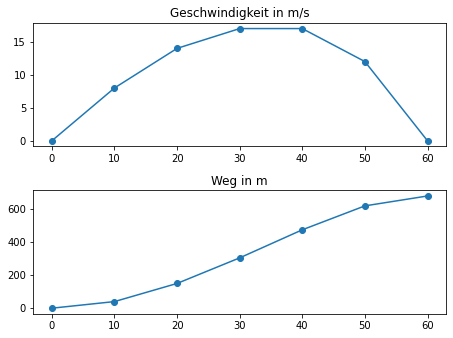

In [ ]:
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate

zeit = np.array([0, 10, 20, 30, 40, 50, 60])                     # in s
geschwindigkeit = np.array([0.0, 8.0, 14.0, 17.0, 17.0, 12.0, 0.0])  # in m/s
import matplotlib.pyplot as plt
weg = integrate.cumulative_trapezoid(geschwindigkeit, zeit, initial=0)
plt.subplot(2, 1, 1)
plt.plot(zeit, geschwindigkeit, 'o-')
plt.title('Geschwindigkeit in m/s')
plt.subplot(2, 1, 2)
plt.plot(zeit, weg, 'o-')
plt.title('Weg in m')
plt.tight_layout()
plt.show()
```

</details>

#### Aufgabe 4.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import integrate

x = np.array([0, 1, 2, 3])
y = np.array([2, 2, 2, 2])
print(integrate.cumulative_trapezoid(y, x, initial=0))
print(np.gradient(np.array([0, 3, 6, 9]), x))

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[0. 2. 4. 6.]
[3. 3. 3. 3.]
```

- Unter einer konstanten Funktion 2 wächst die Fläche um 2 pro Schritt: `[0. 2. 4. 6.]`.
- Die Werte `0, 3, 6, 9` steigen pro Schritt um 3, die Steigung ist überall `3.`: `[3. 3. 3. 3.]`.

</details>

## 5. Spitzen finden

#### `signal.find_peaks()`

Das Modul `scipy.signal` verarbeitet Messsignale. `signal.find_peaks(y)` findet die **Spitzen** (lokalen Maxima) einer Messreihe:
Stellen, deren Wert größer ist als der ihrer Nachbarn. Es gibt ein Tupel zurück: ein Array mit den **Indizes** der Spitzen und ein
Dictionary mit weiteren Angaben (das man meist nicht braucht). Mit den Indizes holt man die Zeiten und Werte aus den Arrays.

In [ ]:
import numpy as np
from scipy import signal

y = np.array([1, 3, 2, 2, 5, 4, 6, 1, 2, 1])
spitzen, eigenschaften = signal.find_peaks(y)
print(spitzen)
print(y[spitzen])

#### Kleine Spitzen aussortieren

Echte Messreihen haben viele kleine Zacken. Mit Parametern sortiert man sie aus:

| Parameter | Bedeutung |
|---|---|
| `height=4` | nur Spitzen, die mindestens 4 hoch sind |
| `distance=5` | Spitzen müssen mindestens 5 Messpunkte auseinander liegen (von zu nahen bleibt die höhere) |
| `prominence=2` | die Spitze muss mindestens 2 über ihre Umgebung herausragen (*Prominenz*, wie bei Berggipfeln) |

**Tiefpunkte** findet man als Spitzen von `-y`.

In [ ]:
import numpy as np
from scipy import signal

y = np.array([1, 3, 2, 2, 5, 4, 6, 1, 2, 1])
print(signal.find_peaks(y, height=4)[0])
print(signal.find_peaks(y, distance=3)[0])
print(signal.find_peaks(y, prominence=2)[0])
print(signal.find_peaks(-y)[0])

#### Aufgabe 5.1

Finde alle Spitzen der Messreihe. Gib ihre Indizes und ihre Werte aus.

**Erwartete Ausgabe:**
```
[1 3 6 9]
[4 6 8 7]
```

In [ ]:
import numpy as np
from scipy import signal

werte = np.array([2, 4, 3, 6, 6, 5, 8, 2, 3, 7, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

werte = np.array([2, 4, 3, 6, 6, 5, 8, 2, 3, 7, 1])
spitzen, eigenschaften = signal.find_peaks(werte)
print(spitzen)
print(werte[spitzen])
```

</details>

#### Aufgabe 5.2

Finde in derselben Messreihe die Tiefpunkte (Indizes und Werte).

**Erwartete Ausgabe:**
```
[2 5 7]
[3 5 2]
```

In [ ]:
import numpy as np
from scipy import signal

werte = np.array([2, 4, 3, 6, 6, 5, 8, 2, 3, 7, 1])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

werte = np.array([2, 4, 3, 6, 6, 5, 8, 2, 3, 7, 1])
tief, eigenschaften = signal.find_peaks(-werte)
print(tief)
print(werte[tief])
```

</details>

#### Aufgabe 5.3

Die Tageshöchsttemperaturen eines Monats sind gegeben. Gib die Tage (Tag 1 ist Index 0) aller Spitzen aus, dann nur die Spitzen ab 20 °C
und dann die Spitzen mit einer Prominenz von mindestens 3.

**Erwartete Ausgabe:**
```
[ 2  5 11 15 18 21 25 28]
[ 5 11 18 21]
[ 5 11 21]
```

In [ ]:
import numpy as np
from scipy import signal

tmax = np.array([14, 16, 15, 18, 21, 19, 17, 17, 20, 22, 23, 19, 16, 15, 17, 16, 18, 20, 19, 22, 24, 21, 18, 17, 19, 18, 15, 16, 14, 15])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

tmax = np.array([14, 16, 15, 18, 21, 19, 17, 17, 20, 22, 23, 19, 16, 15, 17, 16, 18, 20, 19, 22, 24, 21, 18, 17, 19, 18, 15, 16, 14, 15])
tag = np.arange(1, len(tmax) + 1)
print(tag[signal.find_peaks(tmax)[0]])
print(tag[signal.find_peaks(tmax, height=20)[0]])
print(tag[signal.find_peaks(tmax, prominence=3)[0]])
```

</details>

#### Aufgabe 5.4

Die Zelle erzeugt ein Pulssignal mit kleinen Messfehlern. Finde die Herzschläge als Spitzen mit einer Höhe von mindestens 0.5 und gib ihre Anzahl,
die Zeitpunkte (zwei Nachkommastellen) und den Puls in Schlägen pro Minute (mittlerer Abstand der Schläge: `np.diff()`, dann `60 / Abstand`, eine Nachkommastelle) aus.

**Erwartete Ausgabe:**
```
13
[0.2 1.  1.8 2.6 3.4 4.2 5.  5.8 6.6 7.4 8.2 9.  9.8]
75.0
```

In [ ]:
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
spitzen, eigenschaften = signal.find_peaks(messung, height=0.5)
print(len(spitzen))
print(np.round(zeit[spitzen], 2))
abstand = np.diff(zeit[spitzen]).mean()
print(round(60 / abstand, 1))
```

</details>

#### Aufgabe 5.5

Ohne `height` findet `find_peaks()` im Pulssignal viel mehr Spitzen, weil die Messfehler kleine Zacken erzeugen. Gib die Anzahl ohne Parameter aus
und dann die Anzahl mit `distance=20` und mit `prominence=0.5`.

**Erwartete Ausgabe:**
```
127
13
13
```

In [ ]:
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
print(len(signal.find_peaks(messung)[0]))
print(len(signal.find_peaks(messung, distance=20)[0]))
print(len(signal.find_peaks(messung, prominence=0.5)[0]))
```

</details>

#### Aufgabe 5.6

Zeichne das Pulssignal als Linie und markiere die Herzschläge (Höhe mindestens 0.5) mit roten Kreuzen (`'rx'`).
Beschrifte die x-Achse mit `Zeit in s`.

**Erwartete Ausgabe:**

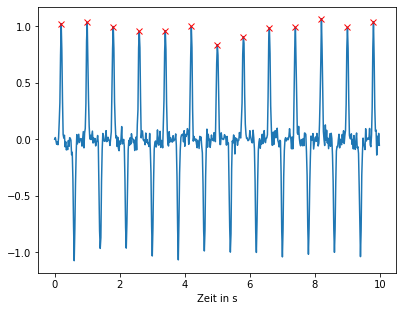

In [ ]:
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
import matplotlib.pyplot as plt
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import signal

rng = np.random.default_rng(7)
zeit = np.arange(0, 10, 0.02)   # 10 Sekunden, 50 Messungen pro Sekunde
messung = np.sin(2 * np.pi * 1.25 * zeit) ** 21 + rng.normal(0, 0.05, len(zeit))
import matplotlib.pyplot as plt
spitzen, eigenschaften = signal.find_peaks(messung, height=0.5)
plt.plot(zeit, messung)
plt.plot(zeit[spitzen], messung[spitzen], 'rx')
plt.xlabel('Zeit in s')
plt.show()
```

</details>

#### Aufgabe 5.7

Bestimme für den Wanderweg aus Abschnitt 1 die Gipfel und Täler (ohne Start und Ziel) nach dem Spline: Werte ihn an 1201 Stellen aus und gib
für jeden Gipfel und jedes Tal den km (zwei Nachkommastellen) und die Höhe (ganze Meter) aus.

**Erwartete Ausgabe:**
```
Gipfel 5.85 520
Gipfel 10.37 564
Tal 7.8 489
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
from scipy import signal
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 2, 4, 6, 8, 10, 12])
hoehe = np.array([320, 380, 470, 520, 490, 560, 430])
from scipy import signal
spline = interpolate.CubicSpline(km, hoehe)
x = np.linspace(0, 12, 1201)
h = spline(x)
for i in signal.find_peaks(h)[0]:
    print('Gipfel', round(x[i], 2), round(h[i]))
for i in signal.find_peaks(-h)[0]:
    print('Tal', round(x[i], 2), round(h[i]))
```

</details>

#### Aufgabe 5.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import numpy as np
from scipy import signal

y = np.array([0, 5, 0, 2, 0, 7, 0])
print(signal.find_peaks(y)[0])
print(signal.find_peaks(y, height=3)[0])
print(signal.find_peaks(y, distance=4)[0])

<details>
<summary>Lösung anzeigen (erst selbst überlegen!)</summary>

**Ausgabe:**
```
[1 3 5]
[1 5]
[1 5]
```

- Spitzen (größer als beide Nachbarn) liegen bei den Indizes 1, 3 und 5: `[1 3 5]`.
- Mit `height=3` fällt die Spitze mit dem Wert 2 weg: `[1 5]`.
- Mit `distance=4` müssen Spitzen mindestens 4 Indizes auseinander liegen. 1 und 5 haben genau den Abstand 4, die 3 liegt zu nah an beiden
  und ist niedriger: `[1 5]`.

</details>

## 6. Gemischte Übungen

#### Aufgabe 6.1

Ein Radfahrer fährt über einen Pass. Für die Messpunkte ist die Höhe bekannt. Gib mit `CubicSpline` aus: die Höhe bei km 7.5 (ganze Meter),
die größte Steigung in Prozent (Spline an 1501 Stellen, eine Nachkommastelle) und die Höhe und Lage des Passes (höchster Punkt, km mit einer Nachkommastelle).

**Erwartete Ausgabe:**
```
1135
8.4
11.5 1313
```

In [ ]:
import numpy as np
from scipy import interpolate

km = np.array([0, 3, 6, 9, 12, 15])
hoehe = np.array([600, 780, 1010, 1240, 1310, 1150])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

km = np.array([0, 3, 6, 9, 12, 15])
hoehe = np.array([600, 780, 1010, 1240, 1310, 1150])
spline = interpolate.CubicSpline(km, hoehe)
print(round(float(spline(7.5))))
x = np.linspace(0, 15, 1501)
print(round(spline(x, 1).max() / 1000 * 100, 1))
h = spline(x)
print(round(x[h.argmax()], 1), round(h.max()))
```

</details>

#### Aufgabe 6.2

Die Einwohnerzahl einer Stadt (in Tausend) wurde alle 10 Jahre gezählt. Passe ein lineares und ein exponentielles Modell an
(`a · e^(k·(t - 1980))`, Startwerte `p0=[50, 0.01]`) und gib für beide `R²` (4 Nachkommastellen) und die Vorhersage für 2040 (eine Nachkommastelle) aus.

**Erwartete Ausgabe:**
```
0.9945 92.9
0.9989 98.9
```

In [ ]:
import numpy as np
from scipy import optimize, stats

jahr = np.array([1980, 1990, 2000, 2010, 2020])
einwohner = np.array([52.0, 57.5, 64.8, 71.2, 79.9])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import optimize, stats

jahr = np.array([1980, 1990, 2000, 2010, 2020])
einwohner = np.array([52.0, 57.5, 64.8, 71.2, 79.9])


def expo(t, a, k):
    return a * np.exp(k * (t - 1980))


r = stats.linregress(jahr, einwohner)
print(round(r.rvalue ** 2, 4), round(r.slope * 2040 + r.intercept, 1))
parameter, kovarianz = optimize.curve_fit(expo, jahr, einwohner, p0=[50, 0.01])
residuen = einwohner - expo(jahr, *parameter)
r2 = 1 - (residuen ** 2).sum() / ((einwohner - einwohner.mean()) ** 2).sum()
print(round(r2, 4), round(expo(2040, *parameter), 1))
```

</details>

#### Aufgabe 6.3

Ein Elektroauto zeichnet seine Leistung (in kW) jede Minute auf, negative Werte bedeuten Rückgewinnung beim Bremsen.
Die verbrauchte Energie ist die Fläche unter der Leistung (kW · min, geteilt durch 60 ergibt kWh). Gib die Energie bis zu jeder Minute
in kWh aus (drei Nachkommastellen) und die Minuten, in denen eine Spitze der Leistung über 30 kW liegt.

**Erwartete Ausgabe:**
```
[0.    0.15  0.592 1.067 1.375 1.433 1.467 1.883 2.408 2.575 2.533]
[2 7]
```

In [ ]:
import numpy as np
from scipy import integrate, signal

minute = np.arange(11)
leistung = np.array([0, 18, 35, 22, 15, -8, 12, 38, 25, -5, 0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import integrate, signal

minute = np.arange(11)
leistung = np.array([0, 18, 35, 22, 15, -8, 12, 38, 25, -5, 0])
energie = integrate.cumulative_trapezoid(leistung, minute, initial=0) / 60
print(np.round(energie, 3))
print(minute[signal.find_peaks(leistung, height=30)[0]])
```

</details>

#### Aufgabe 6.4

Auf einer Teststrecke wird alle 2 Sekunden die Geschwindigkeit gemessen. Interpoliere sie mit `CubicSpline` und berechne den Weg
in den ersten 20 Sekunden zweimal: mit `spline.integrate()` und mit `np.trapezoid()` aus den Messwerten. Runde auf eine Nachkommastelle.

**Erwartete Ausgabe:**
```
258.8
258.0
```

In [ ]:
import numpy as np
from scipy import interpolate

zeit = np.arange(0, 21, 2)
v = np.array([0.0, 4.5, 8.5, 11.5, 14.0, 15.5, 16.5, 17.0, 17.0, 16.5, 16.0])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate

zeit = np.arange(0, 21, 2)
v = np.array([0.0, 4.5, 8.5, 11.5, 14.0, 15.5, 16.5, 17.0, 17.0, 16.5, 16.0])
spline = interpolate.CubicSpline(zeit, v)
print(round(float(spline.integrate(0, 20)), 1))
print(round(np.trapezoid(v, zeit), 1))
```

</details>

#### Aufgabe 6.5

Suche dir eine eigene Messreihe (z. B. Temperaturen deiner Stadt, Wasserstände eines Flusses) und werte sie aus: interpoliere sie,
passe ein passendes Modell mit `curve_fit()` an, finde die Spitzen und zeichne alles in ein Diagramm.

In [ ]:
# your code

<details>
<summary>Beispiellösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from scipy import interpolate, optimize, signal
import matplotlib.pyplot as plt

monat = np.arange(1, 13)
temperatur = np.array([1.5, 2.5, 6.0, 10.0, 14.5, 17.5, 19.5, 19.0, 15.0, 10.5, 5.5, 2.5])


def modell(t, m, a, c):
    return m + a * np.sin(2 * np.pi * (t - c) / 12)


parameter, kovarianz = optimize.curve_fit(modell, monat, temperatur, p0=[10, 9, 4])
print(np.round(parameter, 2))
spline = interpolate.CubicSpline(monat, temperatur)
x = np.linspace(1, 12, 200)
print(monat[signal.find_peaks(temperatur)[0]])
plt.plot(monat, temperatur, 'ko')
plt.plot(x, spline(x), label='Spline')
plt.plot(x, modell(x, *parameter), label='Modell')
plt.legend()
plt.show()
```

</details>